# Quy luật hành vi duyệt web cho log tổng hợp

In [1]:
%matplotlib inline
import datetime as dt
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import yaml
from scipy import optimize, stats

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent.parent
data_dir = repo_root / "data" / "generator" / "eda" / "raw"
rng = np.random.default_rng(20260724)
plt.rcParams["figure.figsize"] = (10, 3.6)
pl.Config.set_tbl_rows(40)


def percent(values):
    return np.round(np.asarray(values) * 100, 1)

## 0. Dữ liệu và cohort

Nguồn: sự kiện eCommerce Behavior tháng 10/2019. Một phiên là một `user_session` (được băm thành số để tiết kiệm bộ nhớ). Mọi phiên có sự kiện ngày 1/10 hoặc 31/10 (giờ UTC) đều bị loại: phiên ngày 1/10 có thể đã bắt đầu từ tháng 9, còn phiên ngày 31/10 có thể kéo sang tháng 11 (file tháng 11 không được dùng). Nhờ vậy không phiên nào bị cắt ở biên; đổi lại cohort còn 29 ngày, từ 2/10 đến 30/10.

Nhóm `apparel`: phiên mà mọi sự kiện có `category_code` đều thuộc nhóm `apparel` (và có ít nhất một sự kiện như vậy).

In [2]:
SCHEMA = {"user_session": pl.Utf8, "category_code": pl.Utf8, "brand": pl.Utf8}


raw = (
    pl.scan_csv(data_dir / "ecommerce_behavior" / "2019-Oct.csv", schema_overrides=SCHEMA)
    .select("event_time", "event_type", "product_id", "user_id", "user_session", "category_code")
    .with_columns(ts=pl.col("event_time").str.replace(" UTC", "").str.to_datetime(time_zone="UTC"))
    .collect(engine="streaming")
)
raw.select("ts", "event_type", "user_session", "category_code").null_count()

ts,event_type,user_session,category_code
u32,u32,u32,u32
0,0,2,13515609


In [3]:
raw = raw.filter(pl.col("user_session").is_not_null())
all_events = raw.select(
    "ts",
    day=pl.col("ts").dt.date(),
    event_type=pl.col("event_type").cast(pl.Categorical),
    product_id="product_id",
    user_id="user_id",
    session=pl.col("user_session").hash(),
    category_top=pl.col("category_code").str.split(".").list.first().fill_null("(null)").cast(pl.Categorical),
    has_category=pl.col("category_code").is_not_null(),
    is_apparel=pl.col("category_code").str.starts_with("apparel").fill_null(False),
)
del raw
boundary = all_events.filter(pl.col("day").is_in([dt.date(2019, 10, 1), dt.date(2019, 10, 31)])).select("session").unique()
events = all_events.join(boundary, on="session", how="anti").sort("session", "ts")
del all_events
sessions = events.group_by("session").agg(
    user_id=pl.col("user_id").first(),
    start=pl.col("ts").min(),
    end=pl.col("ts").max(),
    views=(pl.col("event_type") == "view").sum(),
    carts=(pl.col("event_type") == "cart").sum(),
    purchases=(pl.col("event_type") == "purchase").sum(),
    apparel=pl.col("has_category").any() & (pl.col("is_apparel") | ~pl.col("has_category")).all(),
).with_columns(buying=pl.col("purchases") > 0)
print(f"{boundary.height:,} phiên chạm biên bị loại; còn {sessions.height:,} phiên, {events.height:,} sự kiện")
print(f"phiên có mua: {sessions['buying'].sum():,}; phiên apparel: {sessions['apparel'].sum():,}, "
      f"trong đó có mua: {sessions.filter(pl.col('apparel'))['buying'].sum():,}")
events.select("ts").describe()

550,170 phiên chạm biên bị loại; còn 8,694,251 phiên, 39,945,832 sự kiện
phiên có mua: 595,973; phiên apparel: 293,861, trong đó có mua: 6,949


statistic,ts
str,str
"""count""","""39945832"""
"""null_count""","""0"""
"""mean""","""2019-10-16 13:08:00.175431+00:…"
"""std""",null
"""min""","""2019-10-02 00:00:08+00:00"""
"""25%""","""2019-10-09 16:13:47+00:00"""
"""50%""","""2019-10-16 12:05:27+00:00"""
"""75%""","""2019-10-23 10:23:45+00:00"""
"""max""","""2019-10-30 23:59:56+00:00"""


### 0.1. Sự kiện giỏ hàng bị ghi nhận thiếu

Mọi lượt mua đều phải đi qua giỏ hàng. Vì vậy, tỷ lệ lượt mua (cặp phiên × sản phẩm) có sự kiện `cart` tương ứng chính là **tỷ lệ ghi nhận giỏ hàng** của hệ thống thu thập dữ liệu.

In [4]:
purchase_pairs = events.filter(pl.col("event_type") == "purchase").group_by("session", "product_id").agg(
    day=pl.col("day").min(), category_top=pl.col("category_top").first()
)
cart_pairs = events.filter(pl.col("event_type") == "cart").select("session", "product_id").unique().with_columns(has_cart=pl.lit(True))
purchase_pairs = purchase_pairs.join(cart_pairs, on=["session", "product_id"], how="left").with_columns(pl.col("has_cart").fill_null(False))
(
    purchase_pairs.group_by("category_top")
    .agg(purchases=pl.len(), recorded_share=pl.col("has_cart").mean().round(3))
    .sort("purchases", descending=True)
)

category_top,purchases,recorded_share
cat,u32,f64
"""electronics""",366563,0.61
"""(null)""",155760,0.175
"""appliances""",67649,0.398
"""computers""",24522,0.33
"""auto""",9622,0.268
"""furniture""",7302,0.085
"""apparel""",7283,0.001
"""construction""",6995,0.387
"""kids""",4938,0.128


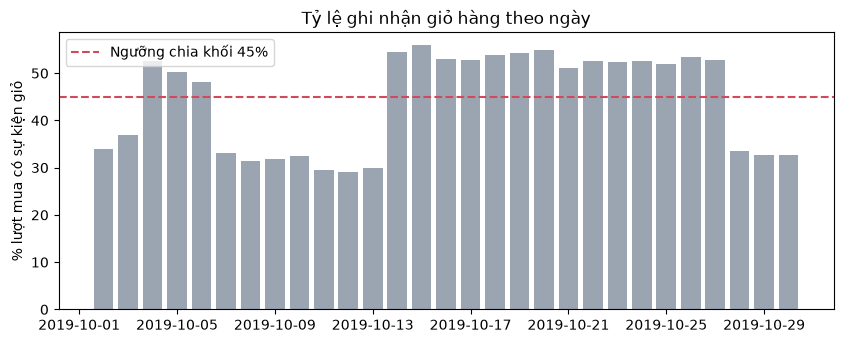

block,days,first_day,last_day,recorded_share
str,u32,date,date,f64
"""cao""",17,2019-10-04,2019-10-27,0.528241
"""thấp""",12,2019-10-02,2019-10-30,0.320427


In [5]:
recording_by_day = purchase_pairs.group_by("day").agg(recorded_share=pl.col("has_cart").mean(), purchases=pl.len()).sort("day")
day_block = recording_by_day.select("day", block=pl.when(pl.col("recorded_share") >= 0.45).then(pl.lit("cao")).otherwise(pl.lit("thấp")))
fig, ax = plt.subplots()
ax.bar(recording_by_day["day"], recording_by_day["recorded_share"] * 100, color="#9aa5b1")
ax.axhline(45, color="#d1495b", linestyle="--", label="Ngưỡng chia khối 45%")
ax.set(ylabel="% lượt mua có sự kiện giỏ", title="Tỷ lệ ghi nhận giỏ hàng theo ngày")
ax.legend()
plt.show()
(
    recording_by_day.join(day_block, on="day")
    .group_by("block")
    .agg(days=pl.len(), first_day=pl.col("day").min(), last_day=pl.col("day").max(),
         recorded_share=(pl.col("recorded_share") * pl.col("purchases")).sum() / pl.col("purchases").sum())
    .sort("block")
)

**Nhận xét:**
- Sau khi loại 550.170 phiên chạm biên, cohort còn **8.694.251 phiên** và 39,9 triệu sự kiện trong 29 ngày (2/10–30/10). Trong đó có 595.973 phiên có mua.
- Nhóm `apparel` có 293.861 phiên, trong đó 6.949 phiên có mua: đủ để so sánh các quy luật về phiên, nhịp thời gian và hành trình.
- **Giỏ hàng bị ghi nhận thiếu:** chỉ 61% lượt mua đồ điện tử có sự kiện giỏ đi kèm, đồ gia dụng 40%, và `apparel` gần như bằng 0. Theo ngày, tỷ lệ này nhảy giữa hai mức: khoảng **53%** (17 ngày, khối "cao") và khoảng **32%** (12 ngày, khối "thấp"). Mức nhảy theo khối ngày như vậy cho thấy hệ thống thu thập bị thay đổi, không phải hành vi khách.

Hệ quả: tỷ lệ thêm giỏ không đo trực tiếp được (mục 3 hiệu chỉnh lại), và nhóm `apparel` không dùng được cho phễu giỏ hàng.

In [6]:
assert events.filter(pl.col("day").is_in([dt.date(2019, 10, 1), dt.date(2019, 10, 31), dt.date(2019, 11, 1)])).height == 0
assert sessions["session"].n_unique() == sessions.height
assert sessions.filter(pl.col("buying")).height > 500_000
assert 250_000 < sessions.filter(pl.col("apparel")).height < 450_000
assert set(day_block["block"].unique()) == {"cao", "thấp"}